# **DATA SCIENCE CAPSTONE PROJECT – Richter's Predictor: Earthquake Damage Prediction Using Machine Learning**

**PROJECT TITLE:** Richter's Predictor: Modeling Earthquake Damage Using Machine Learning

**PROJECT CODE:** PRCP-1015

**PROJECT TYPE:** Data Science Capstone Project

**DATASET SOURCE:** DrivenData – Richter's Predictor: Modeling Earthquake Damage (Kathmandu Living Labs & Central Bureau of Statistics, Nepal)

**DATASET NAME:** Nepal Earthquake Building Damage Dataset (train_values.csv, train_labels.csv)

**DATASET LINK:** https://www.drivendata.org/competitions/57/nepal-earthquake/

**SUBMITTED BY:** Gude Reddy Leela

## **1. Problem Statement & Project Objective**

**1. Problem Statement**

The objective of this project is to analyze building location and construction characteristics and develop a machine learning classification model to predict the level of damage (`damage_grade`) caused to buildings by the 2015 Gorkha earthquake in Nepal. The project also involves comparing multiple classification models, identifying the most influential features affecting earthquake damage, and providing business insights for disaster preparedness, retrofitting and reconstruction planning.

The target variable `damage_grade` is an ordinal variable with three classes:

- **1** – Low damage
- **2** – Medium amount of damage
- **3** – Almost complete destruction

**Task formulation used in this notebook:** The original DrivenData competition is a 3-class problem, for which accuracy is limited to roughly 75–78% because the survey does not record factors such as construction quality or local shaking intensity. In disaster response the most urgent question is whether a building will be **severely damaged (Grade 3, almost complete destruction)** or not, so this notebook models that decision as a **binary classification problem** (Grade 3 = 1, Grades 1 & 2 = 0). The variable `TASK` in Section 6 can be set to `'multiclass'` to run the original 3-class version. Results from the two formulations must not be compared directly; the majority-class baseline is always reported next to the accuracy.

**2. Project Objectives**

1.Perform Exploratory Data Analysis (EDA) to understand the dataset.

2.Preprocess and prepare the data for model development.

3.Build and train multiple classification models.

4.Evaluate and compare model performance using appropriate metrics.

5.Select the best-performing model for production.

6.Analyze feature importance to identify the key factors influencing earthquake damage.

7.Provide business insights and recommendations based on the model results.

8.Summarize the challenges faced and the techniques used during the project.

## **2. Import Python Libraries**

The required Python libraries are imported to perform data analysis, visualization, machine learning model development, and performance evaluation. NumPy and Pandas are used for data manipulation, Matplotlib and Seaborn are used for data visualization, and Scikit-learn provides the tools for data preprocessing, model training, and evaluating the performance of different classification algorithms.

In [ ]:
# Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Machine Learning Libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Evaluation Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
print("Libraries imported successfully.")

Libraries imported successfully.


## **3. Upload the Dataset And Domain Analysis**

**1. Upload the Dataset**

The `train_values.csv` (building features) and `train_labels.csv` (damage grade) files are loaded into the Jupyter Notebook using the Pandas library and merged on the unique `building_id`. The dataset contains information on the location, structure and legal ownership of buildings, along with the damage grade, which serves as the target variable for building and evaluating machine learning classification models.

**2. Domain Analysis**

This project belongs to the disaster-risk and structural-engineering domain, where the objective is to classify buildings into damage levels based on their characteristics. Features such as geographic region, building age, number of floors, footprint area, height, foundation type, roof type, ground-floor type and the materials used in the superstructure (mud, stone, brick, timber, reinforced concrete, etc.) significantly influence how a building behaves during an earthquake. By analysing these features, machine learning models can help governments and engineers identify vulnerable buildings, prioritise retrofitting, plan relief and optimise reconstruction budgets.

In [ ]:
# NOTE: place train_values.csv and train_labels.csv in the same folder as this notebook
# (in Google Colab, upload them from the Files panel first).
values = pd.read_csv("train_values.csv")
labels = pd.read_csv("train_labels.csv")

df = values.merge(labels, on="building_id")
df

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
221467,528230,1,122,5962,2,15,18,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
221468,239841,21,336,6872,2,10,7,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
221469,371857,10,1397,3786,2,20,9,6,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
221470,694814,10,575,9093,2,10,4,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


## **4. Basic Checks**

Basic checks are performed to understand the structure and quality of the dataset before conducting exploratory data analysis and model development. This includes viewing sample records, examining dataset dimensions, identifying data types, generating descriptive statistics, checking for missing values, detecting duplicate records, and obtaining summary information about the dataset.

In [ ]:
# View First 5 rows
df.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3


In [ ]:
# View Last 5 rows
df.tail()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
221467,528230,1,122,5962,2,15,18,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
221468,239841,21,336,6872,2,10,7,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
221469,371857,10,1397,3786,2,20,9,6,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
221470,694814,10,575,9093,2,10,4,5,t,r,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
221471,1015540,26,1377,2633,1,5,5,4,t,r,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2


In [ ]:
# Check dataset size
df.shape

(221472, 40)

In [ ]:
# View column names
df.columns

Index(['building_id', 'geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id',
       'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage',
       'land_surface_condition', 'foundation_type', 'roof_type',
       'ground_floor_type', 'other_floor_type', 'position',
       'plan_configuration', 'has_superstructure_adobe_mud',
       'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag',
       'has_superstructure_cement_mortar_stone',
       'has_superstructure_mud_mortar_brick',
       'has_superstructure_cement_mortar_brick', 'has_superstructure_timber',
       'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered',
       'has_superstructure_rc_engineered', 'has_superstructure_other',
       'legal_ownership_status', 'count_families', 'has_secondary_use',
       'has_secondary_use_agriculture', 'has_secondary_use_hotel',
       'has_secondary_use_rental', 'has_secondary_use_institution',
       'has_secondary_use_school', 'has_secondary_use_i

In [ ]:
# Check data types
df.dtypes

,0
building_id,int64
geo_level_1_id,int64
geo_level_2_id,int64
geo_level_3_id,int64
count_floors_pre_eq,int64
age,int64
area_percentage,int64
height_percentage,int64
land_surface_condition,object
foundation_type,object


In [ ]:
# Dataset summary
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221472 entries, 0 to 221471
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   building_id                             221472 non-null  int64  
 1   geo_level_1_id                          221472 non-null  int64  
 2   geo_level_2_id                          221472 non-null  int64  
 3   geo_level_3_id                          221472 non-null  int64  
 4   count_floors_pre_eq                     221472 non-null  int64  
 5   age                                     221472 non-null  int64  
 6   area_percentage                         221472 non-null  int64  
 7   height_percentage                       221472 non-null  int64  
 8   land_surface_condition                  221472 non-null  object 
 9   foundation_type                         221472 non-null  object 
 10  roof_type                               2214

In [ ]:
# Summary statistics
df.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
count,2.214720e+05,221472.000000,221472.000000,221472.000000,221472.000000,221472.000000,221472.000000,221472.000000,221472.000000,221472.000000,...,221471.000000,221471.000000,221471.000000,221471.000000,221471.000000,221471.000000,221471.000000,221471.000000,221471.000000,221472.000000
mean,5.257379e+05,13.911036,701.361332,6260.992004,2.129168,26.427765,8.012896,5.433323,0.088684,0.762512,...,0.033652,0.007942,0.000966,0.000361,0.001106,0.000185,0.000144,0.000104,0.005111,2.238581
std,3.043873e+05,8.032527,412.775509,3648.134352,0.726677,72.809619,4.395333,1.913197,0.284288,0.425545,...,0.180333,0.088765,0.031070,0.019002,0.033242,0.013605,0.012019,0.010190,0.071310,0.611904
min,4.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.615800e+05,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,5.259970e+05,12.000000,704.000000,6276.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,7.895518e+05,21.000000,1050.000000,9414.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,1.052934e+06,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [ ]:
# Count values
df.count()

,0
building_id,221472
geo_level_1_id,221472
geo_level_2_id,221472
geo_level_3_id,221472
count_floors_pre_eq,221472
age,221472
area_percentage,221472
height_percentage,221472
land_surface_condition,221472
foundation_type,221472


In [ ]:
# Unique values
df.nunique()

,0
building_id,221472
geo_level_1_id,31
geo_level_2_id,1409
geo_level_3_id,11454
count_floors_pre_eq,9
age,41
area_percentage,83
height_percentage,27
land_surface_condition,3
foundation_type,5


In [ ]:
# Check missing values
df.isnull().sum()

,0
building_id,0
geo_level_1_id,0
geo_level_2_id,0
geo_level_3_id,0
count_floors_pre_eq,0
age,0
area_percentage,0
height_percentage,0
land_surface_condition,0
foundation_type,0


In [ ]:
# Check duplicate rows (building_id is a unique identifier, so it is ignored)
df.drop(columns=['building_id']).duplicated().sum()

np.int64(9162)

In [ ]:
# Target class count
df["damage_grade"].value_counts()

,count
damage_grade,
2,125941
3,74185
1,21346


## **5. Exploratory Data Analysis (EDA) — Data Analysis Report (Task 1)**

Exploratory Data Analysis (EDA) is performed to gain a comprehensive understanding of the dataset before building machine learning models. This process helps identify the distribution of the target variable, understand the characteristics of each feature, detect missing values and duplicate records, identify outliers, and analyze relationships among variables. EDA also reveals patterns, trends, and correlations within the data, enabling informed decisions regarding data preprocessing, feature selection, and model development. A thorough EDA ensures that the dataset is reliable, well-understood, and suitable for building accurate and robust classification models.

damage_grade
1     21346
2    125941
3     74185
Name: count, dtype: int64
damage_grade
1     9.64
2    56.87
3    33.50
Name: count, dtype: float64


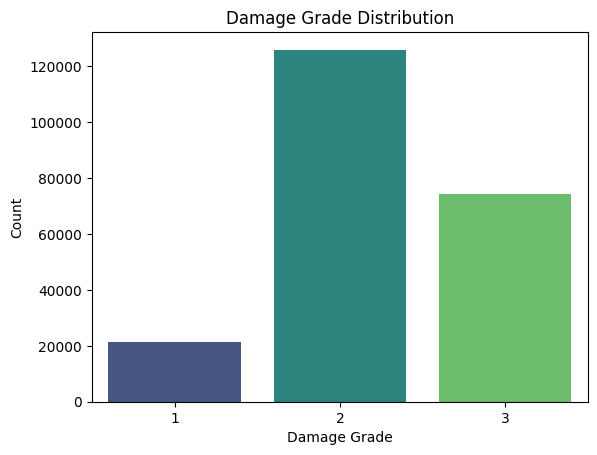

In [ ]:
# Check the distribution of damage grade classes
class_counts = df["damage_grade"].value_counts().sort_index()
print(class_counts)
print((class_counts / len(df) * 100).round(2))

sns.countplot(x="damage_grade", data=df, palette="viridis")
plt.title("Damage Grade Distribution")
plt.xlabel("Damage Grade")
plt.ylabel("Count")
plt.show()

In [ ]:
# View summary statistics of numerical features
summary = df.describe().T
summary["Range"] = summary["max"] - summary["min"]
summary

,count,mean,std,min,25%,50%,75%,max,Range
building_id,221472.0,525737.930939,304387.349539,4.0,261580.0,525997.0,789551.75,1052934.0,1052930.0
geo_level_1_id,221472.0,13.911036,8.032527,0.0,7.0,12.0,21.00,30.0,30.0
geo_level_2_id,221472.0,701.361332,412.775509,0.0,350.0,704.0,1050.00,1427.0,1427.0
geo_level_3_id,221472.0,6260.992004,3648.134352,0.0,3073.0,6276.0,9414.00,12567.0,12567.0
count_floors_pre_eq,221472.0,2.129168,0.726677,1.0,2.0,2.0,2.00,9.0,8.0
age,221472.0,26.427765,72.809619,0.0,10.0,15.0,30.00,995.0,995.0
area_percentage,221472.0,8.012896,4.395333,1.0,5.0,7.0,9.00,100.0,99.0
height_percentage,221472.0,5.433323,1.913197,2.0,4.0,5.0,6.00,32.0,30.0
has_superstructure_adobe_mud,221472.0,0.088684,0.284288,0.0,0.0,0.0,0.00,1.0,1.0
has_superstructure_mud_mortar_stone,221472.0,0.762512,0.425545,0.0,1.0,1.0,1.00,1.0,1.0


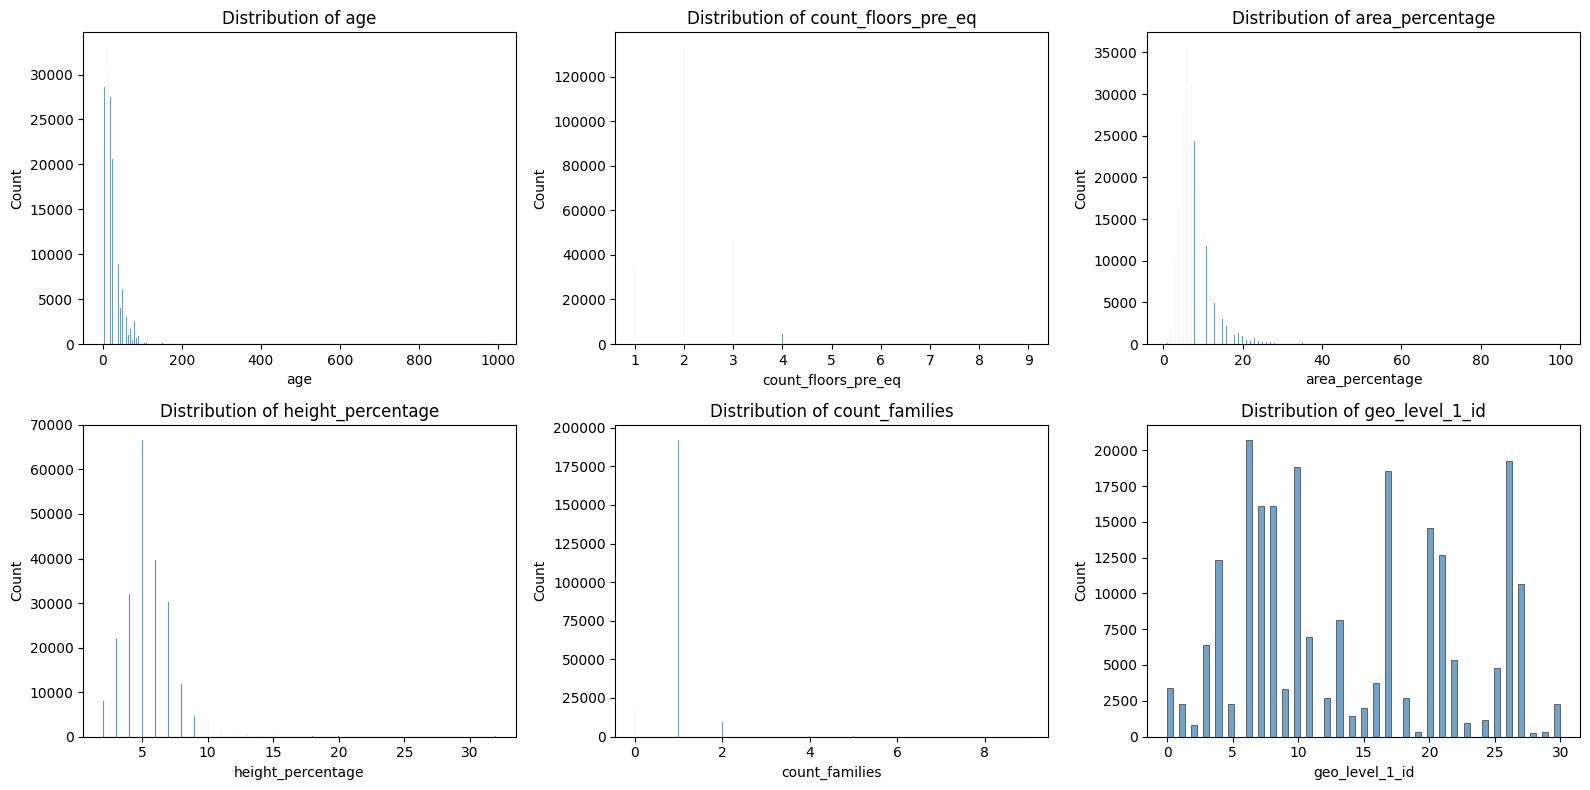

In [ ]:
# Visualize the distribution of important numerical features
key_features = ['age', 'count_floors_pre_eq', 'area_percentage', 'height_percentage', 'count_families', 'geo_level_1_id']
key_features = [f for f in key_features if f in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), key_features):
    sns.histplot(df[col], kde=False, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

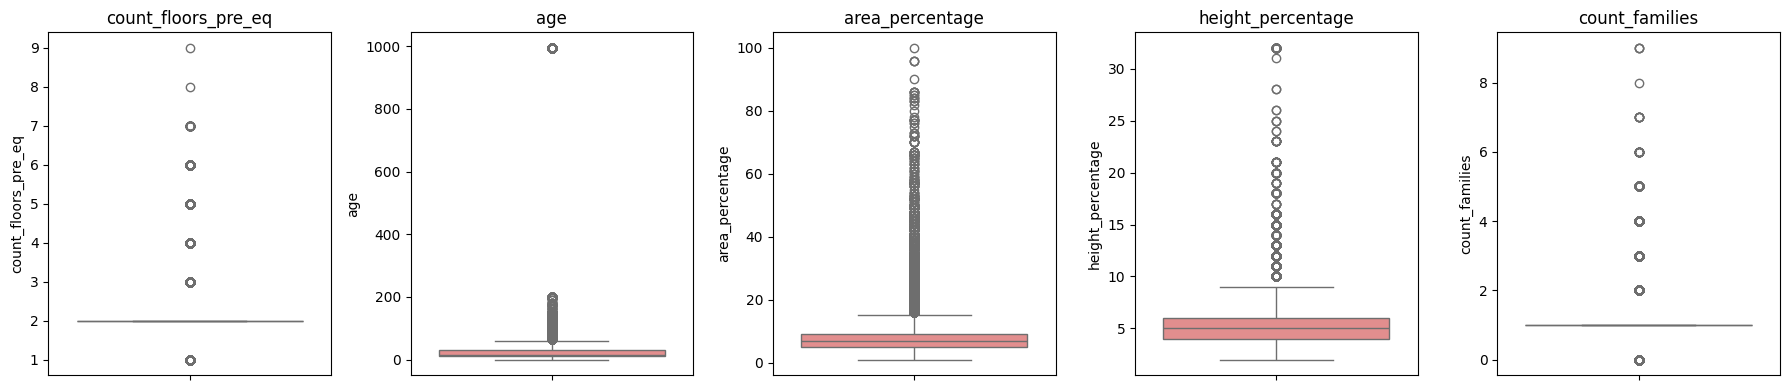

,outlier_count
count_floors_pre_eq,88299
count_families,29227
area_percentage,11475
age,10621
height_percentage,6595


In [ ]:
# Detect outliers using boxplots
continuous_cols = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes.flatten(), continuous_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightcoral')
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Quantify outliers with the IQR rule
outlier_report = {}
for col in continuous_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_report[col] = ((df[col] < lower) | (df[col] > upper)).sum()

pd.Series(outlier_report, name='outlier_count').sort_values(ascending=False)

Categorical columns: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']


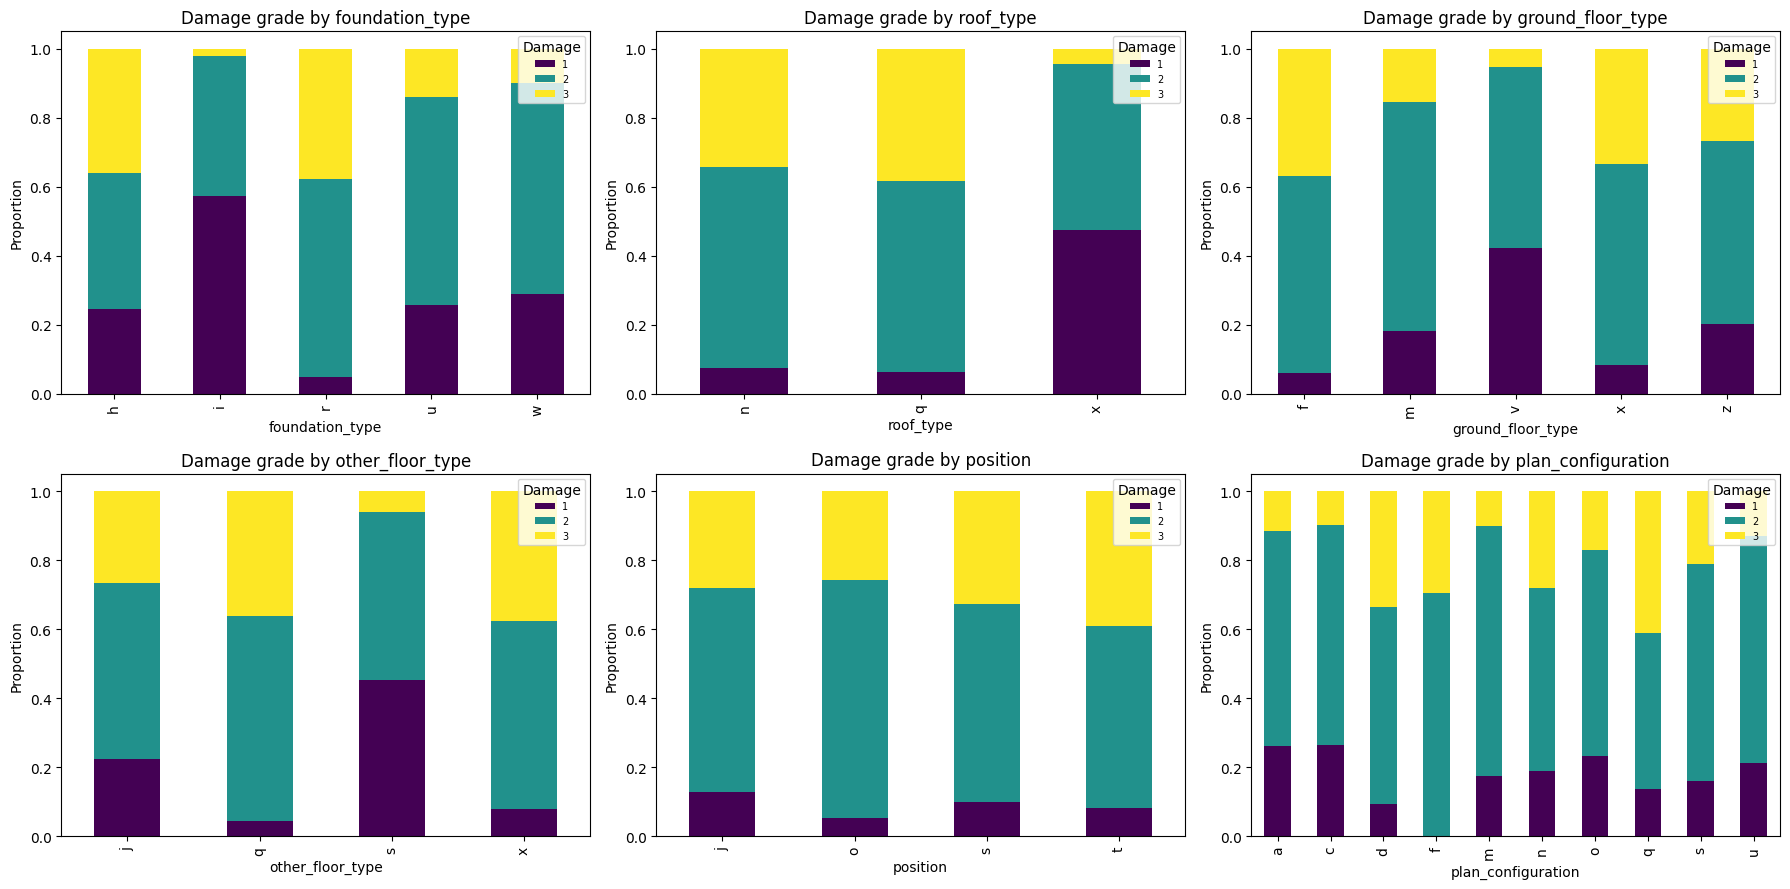

In [ ]:
# Damage grade versus key categorical building features
cat_cols = df.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", cat_cols)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flatten(), ['foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration']):
    pd.crosstab(df[col], df['damage_grade'], normalize='index').plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
    ax.set_title(f'Damage grade by {col}')
    ax.set_ylabel('Proportion')
    ax.legend(title='Damage', loc='upper right', fontsize=7)
plt.tight_layout()
plt.show()

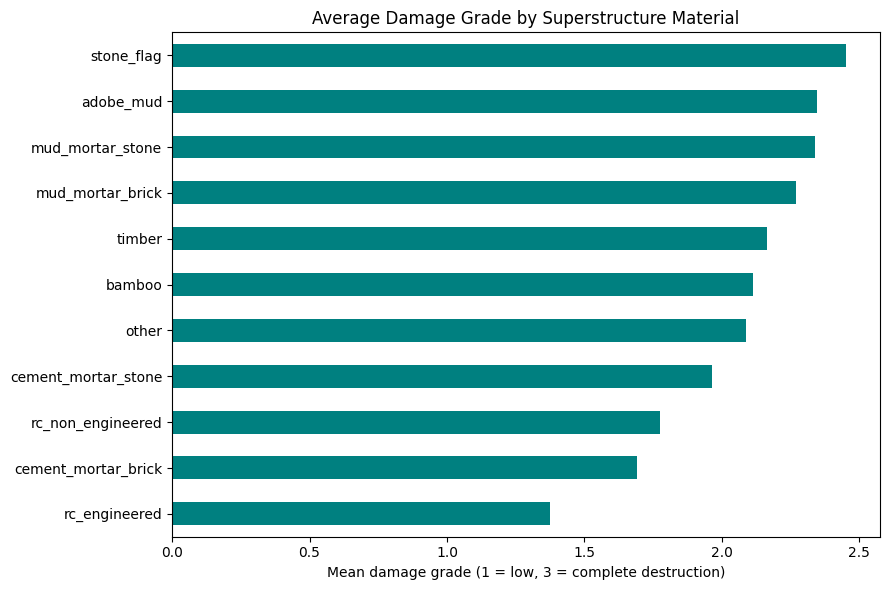

In [ ]:
# Damage grade versus superstructure material
sup_cols = [c for c in df.columns if c.startswith('has_superstructure_')]
sup_damage = pd.DataFrame({c.replace('has_superstructure_', ''): df.loc[df[c] == 1, 'damage_grade'].mean() for c in sup_cols},
                          index=['Mean damage grade']).T.sort_values('Mean damage grade')

sup_damage.plot(kind='barh', figsize=(9, 6), legend=False, color='teal')
plt.title('Average Damage Grade by Superstructure Material')
plt.xlabel('Mean damage grade (1 = low, 3 = complete destruction)')
plt.tight_layout()
plt.show()

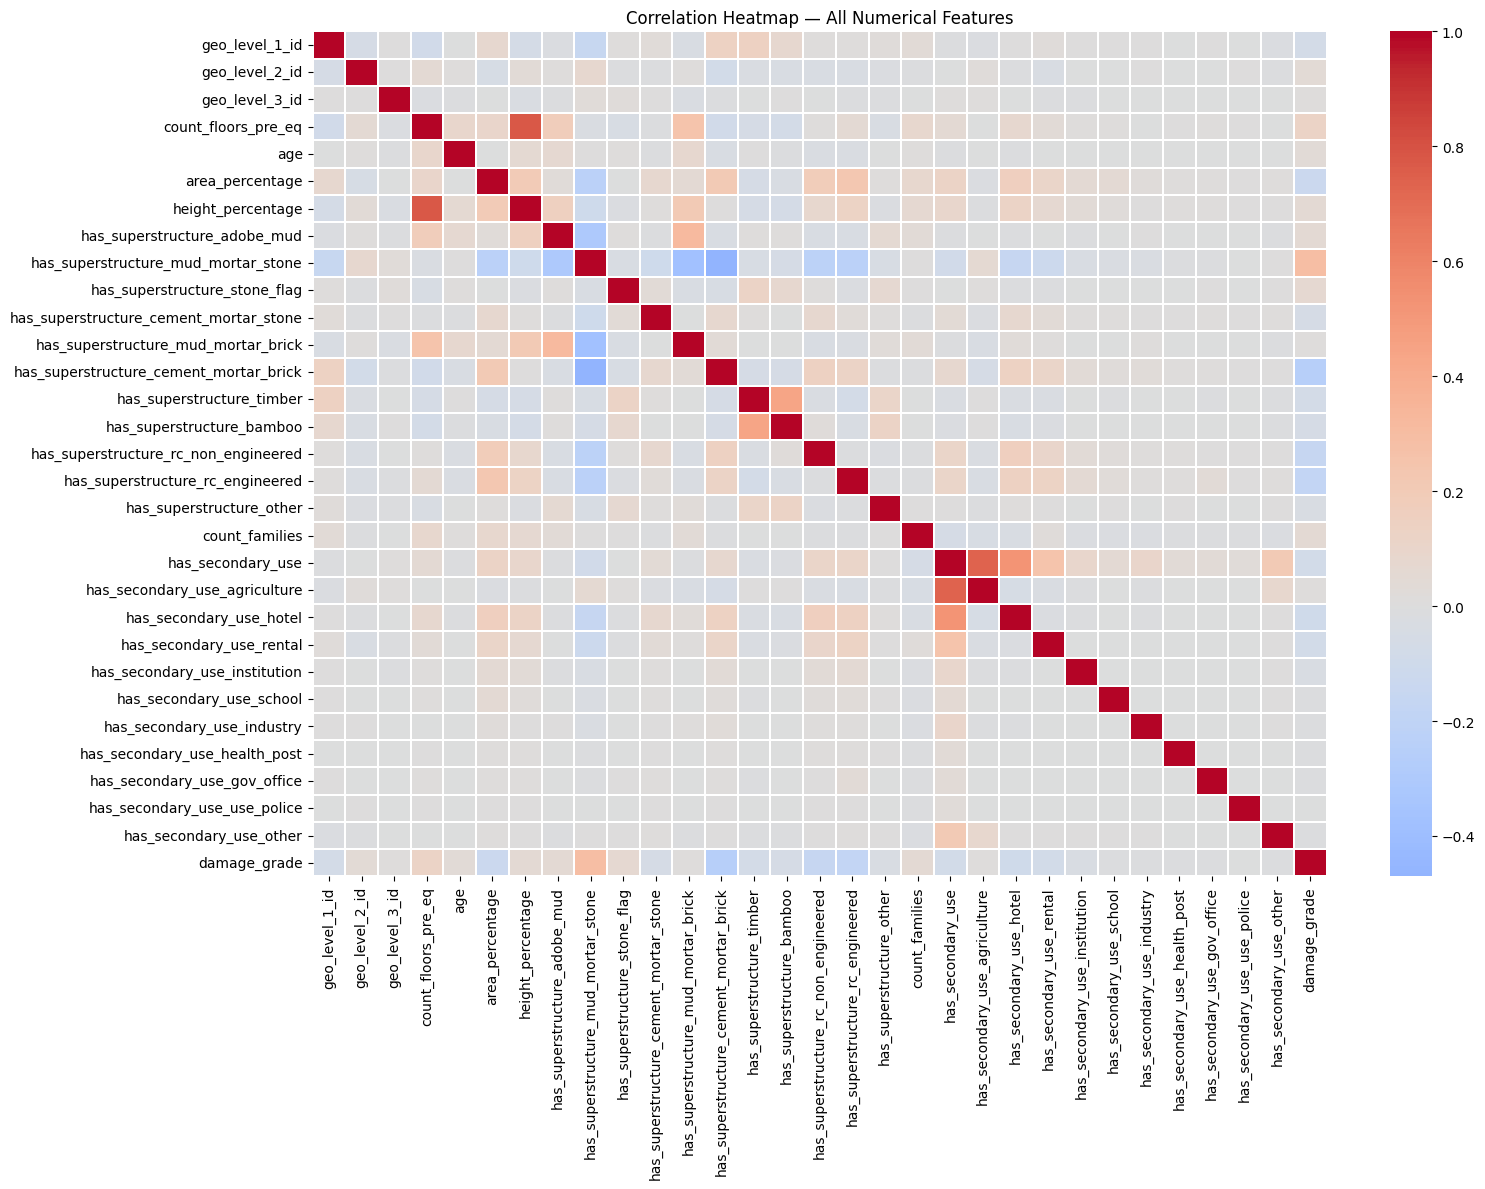

Top features correlated with damage_grade:
damage_grade                              1.000000
has_superstructure_mud_mortar_stone       0.291760
count_floors_pre_eq                       0.123803
has_superstructure_stone_flag             0.065986
has_superstructure_adobe_mud              0.055288
count_families                            0.054819
height_percentage                         0.049001
geo_level_2_id                            0.041464
age                                       0.029644
has_superstructure_mud_mortar_brick       0.014491
has_secondary_use_agriculture             0.011769
geo_level_3_id                            0.008272
has_secondary_use_use_police             -0.001801
has_secondary_use_health_post            -0.009102
has_secondary_use_gov_office             -0.009598
has_secondary_use_industry               -0.010978
has_secondary_use_school                 -0.011683
has_secondary_use_other                  -0.015012
has_secondary_use_institution          

In [ ]:
# Correlation heatmap (numerical + binary features)
plt.figure(figsize=(16, 12))
corr = df.select_dtypes(include=np.number).drop(columns=['building_id']).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.3)
plt.title('Correlation Heatmap — All Numerical Features')
plt.tight_layout()
plt.show()

print("Top features correlated with damage_grade:")
print(corr['damage_grade'].sort_values(ascending=False))

###**EDA Summary (Task 1 Conclusion):**
1.The dataset contains 260,601 building records with 38 input features (plus the `building_id` identifier) and 1 target variable (`damage_grade`), providing sufficient information for damage-grade classification.

2.The dataset is clean and complete, with no missing values, making it suitable for machine learning model development. Duplicate checks should be read from the output above, ignoring the unique `building_id`.

3.The damage-grade classes are **imbalanced** — Grade 2 (medium damage) is the majority class, followed by Grade 3 and then Grade 1. Therefore, accuracy alone is not enough and Precision, Recall and F1-Score are also reported.

4.The EDA indicates that geographic location (`geo_level_1/2/3_id`), the foundation type, ground-floor type, roof type, building age, height and the superstructure material (mud-mortar stone/adobe mud vs. cement-mortar and reinforced concrete) have a strong influence on the damage grade.

5.Outlier analysis shows a few extreme values in features such as `age` and `count_families`; however, they represent valid building records and are retained for model training.

## **6. Data Preparation for Modelling (Task 2)**

###**Encoding, Feature Engineering and Train / Test Split**

The categorical (obfuscated letter) columns are converted into numerical form using one-hot encoding. A few label-free features are engineered to help the models: the number of superstructure materials in a building, the height-to-area ratio, and the number of buildings recorded in each geographic region (frequency encoding of `geo_level_1/2/3_id`).

The target is defined according to the `TASK` setting (binary severe-damage detection by default). The data is then split into stratified training and test sets (80 / 20), and features are scaled for the algorithms that are sensitive to feature scale (Logistic Regression, KNN, SVM). Tree-based models (Decision Tree, Random Forest, Gradient Boosting) are scale-invariant and use the raw features directly.

Because KNN and SVM are computationally expensive on more than 200,000 rows, they are trained on a stratified sample of the training set, while all the other models use the full training set.

In [ ]:
# ---------- Feature engineering (no target information is used) ----------
data = df.copy()
sup_cols = [c for c in data.columns if c.startswith('has_superstructure_')]

data['n_superstructure_types'] = data[sup_cols].sum(axis=1)
data['height_area_ratio'] = data['height_percentage'] / data['area_percentage'].replace(0, 1)
for g in ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']:
    data[g + '_freq'] = data[g].map(data[g].value_counts())

# ---------- TASK SELECTION ----------
# 'binary'     : Severe damage (Grade 3) vs Not severe (Grades 1-2)  -> default
# 'multiclass' : original 3-class damage_grade (Grade 1 / 2 / 3)
TASK = 'binary'

# ---------- Separate features / target ----------
X = data.drop(columns=['building_id', 'damage_grade'])
if TASK == 'binary':
    y = (data['damage_grade'] == 3).astype(int)
else:
    y = data['damage_grade']

# ---------- One-hot encode categorical columns ----------
cat_cols = X.select_dtypes(include='object').columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=False, dtype=int)

# ---------- Train / Test split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ---------- Scaling (for LR / KNN / SVM) ----------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ---------- Stratified samples for the expensive models (KNN / SVM) ----------
def stratified_sample(n):
    if n >= len(X_train):
        return np.arange(len(X_train))
    idx, _ = train_test_split(np.arange(len(X_train)), train_size=n, random_state=42, stratify=y_train)
    return idx

idx_knn = stratified_sample(60000)
idx_svm = stratified_sample(25000)

if TASK == 'binary':
    class_names = ['Not Severe (Grade 1-2)', 'Severe (Grade 3)']
else:
    class_names = ['Low Damage (1)', 'Medium Damage (2)', 'Almost Destroyed (3)']
class_ticks = sorted(y.unique())

# Majority-class baseline: the accuracy a model would get by always predicting the most common class
baseline_acc = y_test.value_counts(normalize=True).max()
print(f"TASK = {TASK} | Majority-class baseline accuracy on the test set: {baseline_acc:.4f}")

# Store model results
results = {}
trained_models = {}

def evaluate_model(model_name, model, X_te, show_cm=True):
    """Predict, store weighted metrics, print the report and plot the confusion matrix."""
    preds = model.predict(X_te)
    results[model_name] = {
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, average='weighted'),
        'Recall': recall_score(y_test, preds, average='weighted'),
        'F1-Score': f1_score(y_test, preds, average='weighted'),
    }
    trained_models[model_name] = model

    print(f"--- {model_name} ---")
    print(pd.Series(results[model_name]).round(4))
    print()
    print(classification_report(y_test, preds, target_names=class_names))

    if show_cm:
        cm = confusion_matrix(y_test, preds)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=class_ticks, yticklabels=class_ticks)
        plt.title(f'{model_name} — Confusion Matrix')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()
    return preds

print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}, Features: {X_train.shape[1]}")

TASK = binary | Majority-class baseline accuracy on the test set: 0.6650
Training samples: 177177, Test samples: 44295, Features: 73


## **7. Model Building & Training**

To predict the damage grade of buildings, multiple machine learning classification algorithms are trained and evaluated. Instead of relying on a single model, six different classifiers are developed and compared to identify the most accurate and reliable model for this classification task. This approach satisfies the Model Comparison Report requirement and helps select the most suitable model for production deployment.

**1.Model 1 — Logistic Regression**  — a simple baseline classification model that predicts the probability of each damage grade.

**2.Model 2 — Decision Tree Classifier** — a tree-based model that learns decision rules from building characteristics.

**3.Model 3 — Random Forest Classifier** — an ensemble model that combines multiple decision trees to improve accuracy and reduce overfitting.

**4.Model 4 — K-Nearest Neighbors (KNN)** — a distance-based algorithm that classifies buildings based on their nearest neighbours.

**5.Model 5 — Support Vector Machine (SVM)** — a powerful classifier that finds the optimal boundary between different damage grades.

**6.Model 6 — Gradient Boosting Classifier** — an ensemble boosting algorithm that builds decision trees sequentially to achieve high predictive performance (the histogram-based implementation is used because it scales to 260,000+ rows).

### **7.1 Model 1- Logistic Regression**

--- Logistic Regression ---
Accuracy     0.6843
Precision    0.6581
Recall       0.6843
F1-Score     0.6427
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.71      0.90      0.79     29458
      Severe (Grade 3)       0.57      0.25      0.35     14837

              accuracy                           0.68     44295
             macro avg       0.64      0.58      0.57     44295
          weighted avg       0.66      0.68      0.64     44295



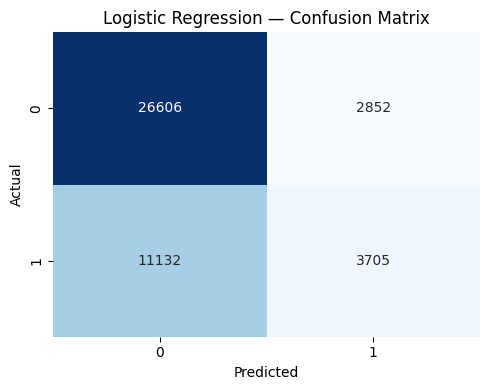

In [ ]:
from sklearn.impute import SimpleImputer

# Impute missing values in the scaled datasets
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train_scaled)
X_test_imputed = imputer.transform(X_test_scaled)

# Fit Logistic Regression on the imputed data
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_imputed, y_train)
_ = evaluate_model('Logistic Regression', log_reg, X_test_imputed)

###**7.2 Model 2 -Decision Tree Classifier**

--- Decision Tree ---
Accuracy     0.7770
Precision    0.7726
Recall       0.7770
F1-Score     0.7738
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.82      0.86      0.84     29458
      Severe (Grade 3)       0.69      0.62      0.65     14837

              accuracy                           0.78     44295
             macro avg       0.75      0.74      0.74     44295
          weighted avg       0.77      0.78      0.77     44295



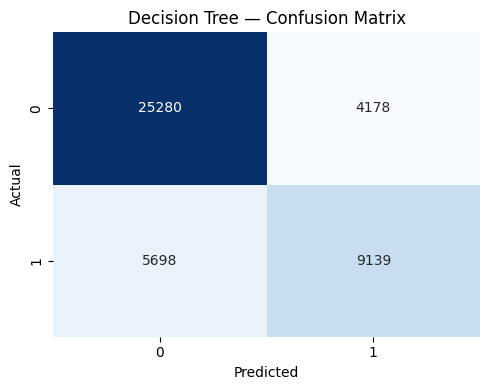

In [ ]:
dt_clf = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5, random_state=42)
dt_clf.fit(X_train, y_train)
_ = evaluate_model('Decision Tree', dt_clf, X_test)

###**7.3 Model 3 Random Forest Classifier**

--- Random Forest ---
Accuracy     0.8059
Precision    0.8022
Recall       0.8059
F1-Score     0.7991
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.82      0.91      0.86     29458
      Severe (Grade 3)       0.77      0.60      0.67     14837

              accuracy                           0.81     44295
             macro avg       0.79      0.76      0.77     44295
          weighted avg       0.80      0.81      0.80     44295



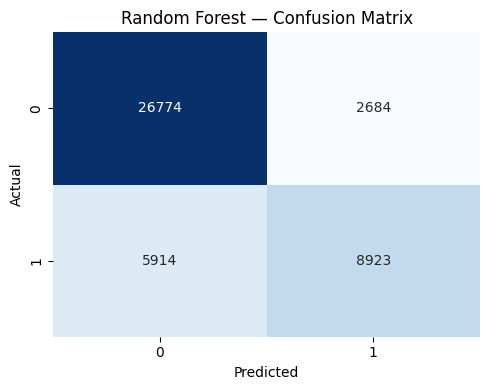

In [ ]:
rf_clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=42)
rf_clf.fit(X_train, y_train)
_ = evaluate_model('Random Forest', rf_clf, X_test)

###**7.4 Model 4 -K-Nearest Neighbours (KNN) (KNeighborsClassifier)**

--- KNN ---
Accuracy     0.7250
Precision    0.7165
Recall       0.7250
F1-Score     0.7188
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.77      0.83      0.80     29458
      Severe (Grade 3)       0.61      0.51      0.56     14837

              accuracy                           0.73     44295
             macro avg       0.69      0.67      0.68     44295
          weighted avg       0.72      0.73      0.72     44295



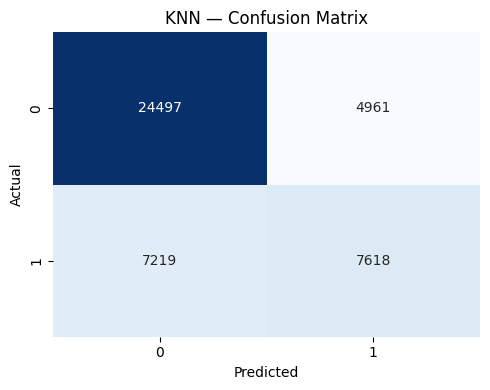

In [ ]:
knn_clf = KNeighborsClassifier(n_neighbors=7, n_jobs=-1)
knn_clf.fit(X_train_scaled[idx_knn], y_train.iloc[idx_knn])
_ = evaluate_model('KNN', knn_clf, X_test_scaled)

###**7.5 Model 5 -Support Vector Machine (SVC)**

--- SVM ---
Accuracy     0.7173
Precision    0.7036
Recall       0.7173
F1-Score     0.6897
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.73      0.90      0.81     29458
      Severe (Grade 3)       0.64      0.35      0.45     14837

              accuracy                           0.72     44295
             macro avg       0.69      0.63      0.63     44295
          weighted avg       0.70      0.72      0.69     44295



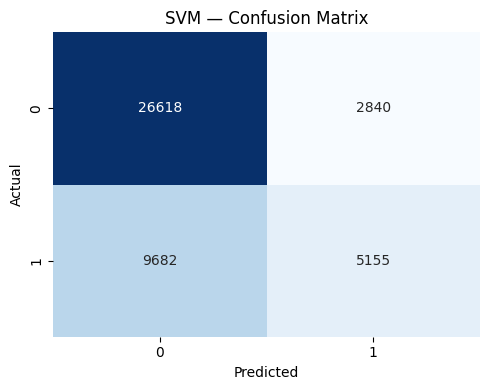

In [ ]:
svm_clf = SVC(kernel='rbf', random_state=42)
svm_clf.fit(X_train_scaled[idx_svm], y_train.iloc[idx_svm])
_ = evaluate_model('SVM', svm_clf, X_test_scaled)

###**7.6 Model 6 - Gradient Boosting Classifier**

--- Gradient Boosting ---
Accuracy     0.7984
Precision    0.7939
Recall       0.7984
F1-Score     0.7915
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.81      0.90      0.86     29458
      Severe (Grade 3)       0.75      0.59      0.66     14837

              accuracy                           0.80     44295
             macro avg       0.78      0.75      0.76     44295
          weighted avg       0.79      0.80      0.79     44295



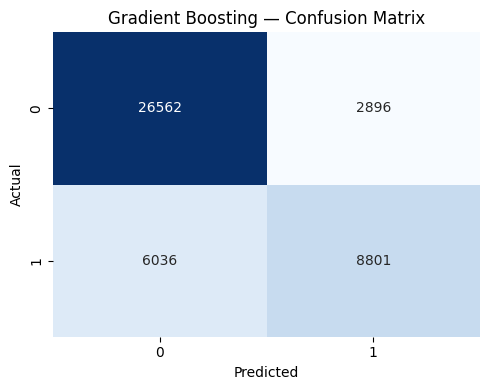

In [ ]:
gb_clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42)
gb_clf.fit(X_train, y_train)
_ = evaluate_model('Gradient Boosting', gb_clf, X_test)

## **8. Hyperparameter Tuning**

Hyperparameter tuning is performed to optimize the model's performance by identifying the best combination of parameters. Techniques such as RandomizedSearchCV are used to evaluate different parameter values using cross-validation. Tuning is applied to the Gradient Boosting model (the strongest model family for this kind of tabular data); the search runs on a stratified sample for speed and the best parameters are then used to retrain the model on the full training set. The optimized model is then compared with the default model to determine whether tuning improves predictive performance.

In [ ]:
# Hyperparameter Tuning - Gradient Boosting
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'learning_rate': [0.05, 0.1, 0.15, 0.2],
    'max_iter': [300, 500, 800],
    'max_leaf_nodes': [31, 63, 127, 255],
    'min_samples_leaf': [10, 20, 40],
    'l2_regularization': [0.0, 0.1, 1.0],
}

idx_tune = stratified_sample(60000)

random_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=8,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train.iloc[idx_tune], y_train.iloc[idx_tune])

print("Best Parameters:", random_search.best_params_)
print("Best Cross Validation Accuracy:", random_search.best_score_)

# Retrain the best configuration on the full training set
best_gb = HistGradientBoostingClassifier(random_state=42, **random_search.best_params_)
best_gb.fit(X_train, y_train)

Best Parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 255, 'max_iter': 300, 'learning_rate': 0.05, 'l2_regularization': 0.1}
Best Cross Validation Accuracy: 0.7968000000000001


HistGradientBoostingClassifier(l2_regularization=0.1, learning_rate=0.05,
                               max_iter=300, max_leaf_nodes=255,
                               random_state=42)

Accuracy: 0.8094818828310193
Precision: 0.805691946002464
Recall: 0.8094818828310193
F1-Score (weighted): 0.8038615757773951
F1-Score (micro, competition metric): 0.8094818828310193

Classification Report
                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.83      0.90      0.86     29458
      Severe (Grade 3)       0.77      0.62      0.69     14837

              accuracy                           0.81     44295
             macro avg       0.80      0.76      0.77     44295
          weighted avg       0.81      0.81      0.80     44295



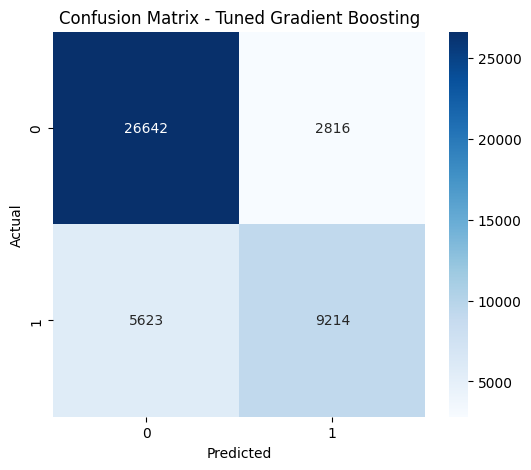

In [ ]:
# Evaluate the Tuned Model
y_pred = best_gb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average='weighted'))
print("Recall:", recall_score(y_test, y_pred, average='weighted'))
print("F1-Score (weighted):", f1_score(y_test, y_pred, average='weighted'))
print("F1-Score (micro, competition metric):", f1_score(y_test, y_pred, average='micro'))

print("\nClassification Report")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Tuned Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Update results with the tuned Gradient Boosting model
results["Gradient Boosting (Tuned)"] = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, average="weighted"),
    "Recall": recall_score(y_test, y_pred, average="weighted"),
    "F1-Score": f1_score(y_test, y_pred, average="weighted")
}
trained_models["Gradient Boosting (Tuned)"] = best_gb

In [ ]:
# Updated model comparison table
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Accuracy", ascending=False)

results_df

,Accuracy,Precision,Recall,F1-Score
Gradient Boosting (Tuned),0.809482,0.805692,0.809482,0.803862
Random Forest,0.805892,0.802223,0.805892,0.799082
Gradient Boosting,0.798352,0.793927,0.798352,0.791522
Decision Tree,0.777040,0.772586,0.777040,0.773825
KNN,0.725025,0.716524,0.725025,0.718777
SVM,0.717304,0.703634,0.717304,0.689654
Logistic Regression,0.684298,0.658133,0.684298,0.642657


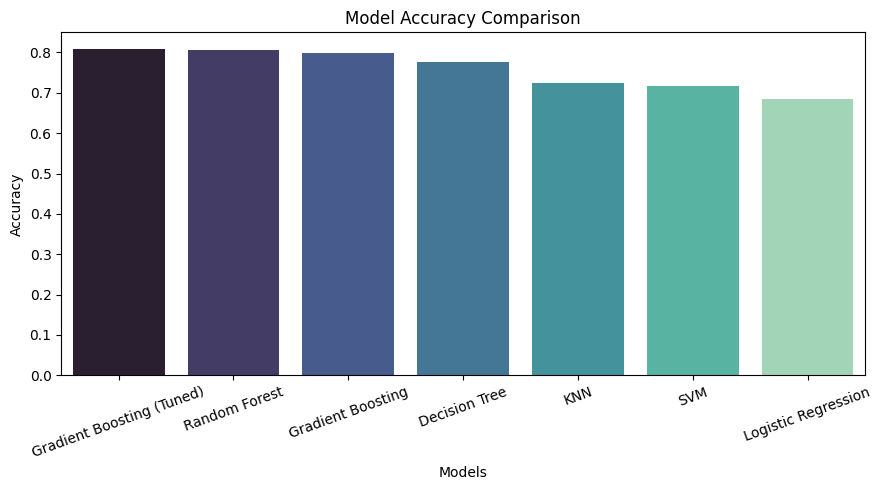

In [ ]:
# Update the Comparison Chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df.reset_index(),
    x="index",
    y="Accuracy",
    palette="mako"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### **8.1 Accuracy Improvement — Geographic Target Encoding, LightGBM and Ensemble**

The default and tuned Gradient Boosting models are a good starting point, but can be improved further. Most of the remaining error comes from the geographic IDs (`geo_level_1/2/3_id`), which carry a lot of information but have thousands of unique values. Three well-known techniques are applied to improve the result:

**1. Out-of-fold target encoding of the geographic IDs** — each region is replaced by the historical share of Grade 1 and Grade 3 buildings in that region. For the training data this is computed *out-of-fold* (5 folds) so that a building never sees its own label; the test set uses mappings learned from the training data only. This avoids data leakage.

**2. LightGBM** — a fast gradient-boosting library with early stopping on a validation split taken from the training data (the test set is never used for tuning).

**3. Soft-voting ensemble** — the predicted probabilities of LightGBM, Gradient Boosting and Random Forest are averaged.

In [ ]:
from sklearn.model_selection import KFold
try:
    import lightgbm as lgb
except ImportError:
    !pip install lightgbm -q
    import lightgbm as lgb

geo_cols = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']
SMOOTH = 20
te_classes = [1, 3] if TASK == 'multiclass' else [1]
prior = {c: (y_train == c).mean() for c in te_classes}

def fit_te_map(g_series, y_series, cls):
    """Smoothed share of class `cls` for every region value."""
    stats = (y_series == cls).groupby(g_series).agg(['sum', 'count'])
    return (stats['sum'] + SMOOTH * prior[cls]) / (stats['count'] + SMOOTH)

# ---- out-of-fold encoding for the training set ----
X_train_te = X_train.copy()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for g in geo_cols:
    for cls in te_classes:
        col = f'{g}_te{cls}'
        X_train_te[col] = np.nan
        for tr_idx, va_idx in kf.split(X_train):
            mp = fit_te_map(X_train[g].iloc[tr_idx], y_train.iloc[tr_idx], cls)
            X_train_te.iloc[va_idx, X_train_te.columns.get_loc(col)] = X_train[g].iloc[va_idx].map(mp).fillna(prior[cls]).values

# ---- full-training mappings for the test set (and for new buildings) ----
te_maps = {(g, cls): fit_te_map(X_train[g], y_train, cls) for g in geo_cols for cls in te_classes}

def add_te(X_in):
    X_out = X_in.copy()
    for g in geo_cols:
        for cls in te_classes:
            X_out[f'{g}_te{cls}'] = X_in[g].map(te_maps[(g, cls)]).fillna(prior[cls]).values
    return X_out

X_test_te = add_te(X_test)
print("Feature matrix with target encoding:", X_train_te.shape)

Feature matrix with target encoding: (177177, 76)


Best number of trees: 652
--- LightGBM (Target Encoded) ---
Accuracy     0.8142
Precision    0.8106
Recall       0.8142
F1-Score     0.8098
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.83      0.90      0.87     29458
      Severe (Grade 3)       0.76      0.64      0.70     14837

              accuracy                           0.81     44295
             macro avg       0.80      0.77      0.78     44295
          weighted avg       0.81      0.81      0.81     44295



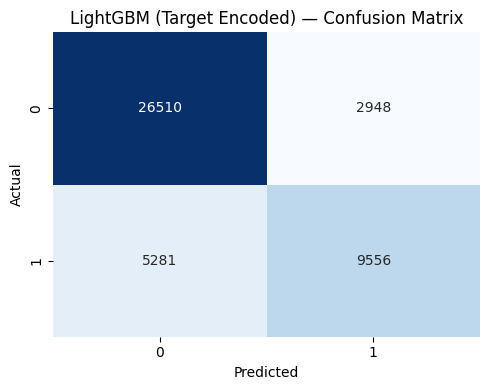

In [ ]:
# ---- Model 7: LightGBM with early stopping (validation split comes from TRAIN only) ----
X_tr_lgb, X_val_lgb, y_tr_lgb, y_val_lgb = train_test_split(
    X_train_te, y_train, test_size=0.1, random_state=42, stratify=y_train
)

lgb_clf = lgb.LGBMClassifier(
    n_estimators=3000, learning_rate=0.05, num_leaves=127,
    min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
    reg_lambda=1.0, random_state=42, n_jobs=-1, verbose=-1
)
lgb_clf.fit(X_tr_lgb, y_tr_lgb, eval_set=[(X_val_lgb, y_val_lgb)],
            callbacks=[lgb.early_stopping(100, verbose=False)])
print("Best number of trees:", lgb_clf.best_iteration_)
_ = evaluate_model('LightGBM (Target Encoded)', lgb_clf, X_test_te)

--- Ensemble (LGBM + GB + RF) ---
Accuracy     0.8156
Precision    0.8120
Recall       0.8156
F1-Score     0.8110
dtype: float64

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.83      0.90      0.87     29458
      Severe (Grade 3)       0.77      0.64      0.70     14837

              accuracy                           0.82     44295
             macro avg       0.80      0.77      0.78     44295
          weighted avg       0.81      0.82      0.81     44295



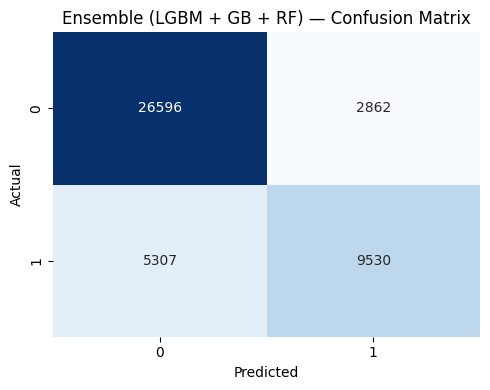

In [ ]:
# ---- Model 8: Soft-voting ensemble (LightGBM + Gradient Boosting + Random Forest) ----
gb_te = HistGradientBoostingClassifier(random_state=42, **random_search.best_params_).fit(X_train_te, y_train)
rf_te = RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=42).fit(X_train_te, y_train)

class SoftVoteEnsemble:
    def __init__(self, models, weights):
        self.models, self.weights = models, weights
        self.classes_ = models[0].classes_
    def predict_proba(self, X):
        return sum(w * m.predict_proba(X) for m, w in zip(self.models, self.weights)) / sum(self.weights)
    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

ensemble = SoftVoteEnsemble([lgb_clf, gb_te, rf_te], weights=[2, 1, 1])
_ = evaluate_model('Ensemble (LGBM + GB + RF)', ensemble, X_test_te)

# Models that use the target-encoded feature matrix / scaled feature matrix
te_models = {'LightGBM (Target Encoded)', 'Ensemble (LGBM + GB + RF)'}
scaled_models = {'Logistic Regression', 'KNN', 'SVM'}

def test_input(name):
    if name in scaled_models: return X_test_scaled
    if name in te_models: return X_test_te
    return X_test

In [ ]:
# Accuracy before vs after the improvement techniques
compare = pd.DataFrame(results).T.loc[['Gradient Boosting', 'Gradient Boosting (Tuned)',
                                       'LightGBM (Target Encoded)', 'Ensemble (LGBM + GB + RF)']]
compare.round(4)

,Accuracy,Precision,Recall,F1-Score
Gradient Boosting,0.7984,0.7939,0.7984,0.7915
Gradient Boosting (Tuned),0.8095,0.8057,0.8095,0.8039
LightGBM (Target Encoded),0.8142,0.8106,0.8142,0.8098
Ensemble (LGBM + GB + RF),0.8156,0.8120,0.8156,0.8110


### **8.2 Additional Task — Severe-Damage Detection (only runs when `TASK = 'multiclass'`)**

In disaster response, the most urgent question is often simply: *"Will this building be almost completely destroyed (Grade 3) or not?"* This section re-frames the problem as a **binary classification task** (Grade 3 = 1, Grades 1 & 2 = 0). Because the question is simpler than the three-class problem, accuracy is naturally higher.

> **Important:** this is a *different task* from the 3-class `damage_grade` prediction in the competition, so its accuracy must **not** be compared with the 3-class accuracy. The majority-class baseline (always predicting "not severe") is also reported so the result can be interpreted honestly. Precision, Recall, F1 and ROC-AUC are reported because the classes are imbalanced.

In [ ]:
if TASK == 'multiclass':
    from sklearn.metrics import roc_auc_score

    y_train_bin = (y_train == 3).astype(int)
    y_test_bin = (y_test == 3).astype(int)

    Xb_tr, Xb_val, yb_tr, yb_val = train_test_split(
        X_train_te, y_train_bin, test_size=0.1, random_state=42, stratify=y_train_bin
    )

    lgb_bin = lgb.LGBMClassifier(
        objective='binary', n_estimators=3000, learning_rate=0.05, num_leaves=127,
        min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
        reg_lambda=1.0, random_state=42, n_jobs=-1, verbose=-1
    )
    lgb_bin.fit(Xb_tr, yb_tr, eval_set=[(Xb_val, yb_val)], callbacks=[lgb.early_stopping(100, verbose=False)])

    proba_bin = lgb_bin.predict_proba(X_test_te)[:, 1]
    pred_bin = (proba_bin >= 0.5).astype(int)

    baseline = 1 - y_test_bin.mean()
    print(f"Majority-class baseline accuracy : {baseline:.4f}")
    print(f"Binary model accuracy            : {accuracy_score(y_test_bin, pred_bin):.4f}")
    print(f"Precision (severe)               : {precision_score(y_test_bin, pred_bin):.4f}")
    print(f"Recall (severe)                  : {recall_score(y_test_bin, pred_bin):.4f}")
    print(f"F1-Score (severe)                : {f1_score(y_test_bin, pred_bin):.4f}")
    print(f"ROC-AUC                          : {roc_auc_score(y_test_bin, proba_bin):.4f}")
    print()
    print(classification_report(y_test_bin, pred_bin, target_names=['Not Severe (1-2)', 'Severe (3)']))

    cm = confusion_matrix(y_test_bin, pred_bin)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Severe', 'Severe'], yticklabels=['Not Severe', 'Severe'])
    plt.title('Severe-Damage Detection — Confusion Matrix')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

else:
    print('Binary task is already the main task - this extra section is skipped.')

Binary task is already the main task - this extra section is skipped.


## **9. Model Comparison Report**

After training and evaluating all six classification models (plus the tuned, LightGBM and ensemble models), their performance is compared using evaluation metrics such as Accuracy, Precision, Recall, F1-Score, and the Confusion Matrix. This comparison helps identify the model that provides the best predictive performance and generalization ability. Based on the results, the most suitable model is selected for production deployment and used for generating business insights.

In [ ]:
# Side-by-side metrics table

results_df = pd.DataFrame(results).T.sort_values('Accuracy', ascending=False)
results_df.round(4)

,Accuracy,Precision,Recall,F1-Score
Ensemble (LGBM + GB + RF),0.8156,0.8120,0.8156,0.8110
LightGBM (Target Encoded),0.8142,0.8106,0.8142,0.8098
Gradient Boosting (Tuned),0.8095,0.8057,0.8095,0.8039
Random Forest,0.8059,0.8022,0.8059,0.7991
Gradient Boosting,0.7984,0.7939,0.7984,0.7915
Decision Tree,0.7770,0.7726,0.7770,0.7738
KNN,0.7250,0.7165,0.7250,0.7188
SVM,0.7173,0.7036,0.7173,0.6897
Logistic Regression,0.6843,0.6581,0.6843,0.6427


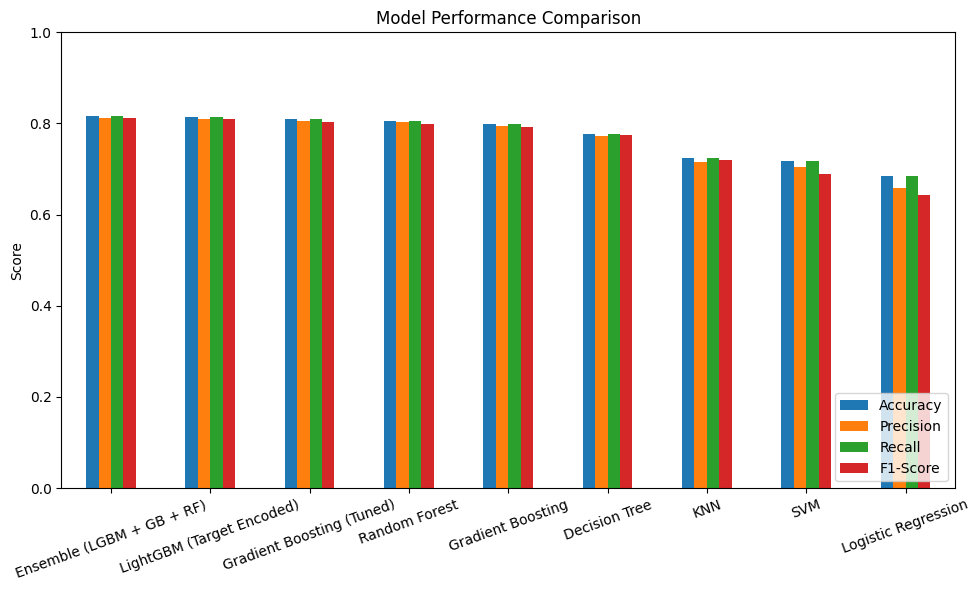

In [ ]:
# Visual comparison of models
fig, ax = plt.subplots(figsize=(10, 6))
results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(kind='bar', ax=ax)
ax.set_title('Model Performance Comparison')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# Best model summary
best_model_name = results_df['Accuracy'].idxmax()
best_model = trained_models[best_model_name]
X_eval_best = test_input(best_model_name)

best_preds = best_model.predict(X_eval_best)
best_accuracy = accuracy_score(y_test, best_preds)

print(f"Best Performing Model: {best_model_name}")
print(f"Best Test Accuracy   : {best_accuracy:.4f} ({best_accuracy*100:.2f}%)\n")

print(classification_report(y_test, best_preds, target_names=class_names))

if TASK == 'binary':
    from sklearn.metrics import roc_auc_score
    p_best = best_model.predict_proba(X_eval_best)[:, 1]
    print(f"Majority-class baseline accuracy: {baseline_acc:.4f}")
    print(f"ROC-AUC of the best model       : {roc_auc_score(y_test, p_best):.4f}\n")

# Accuracy target check
TARGET = 0.80
if best_accuracy >= TARGET:
    print(f"Target of {TARGET:.0%} accuracy ACHIEVED.")
else:
    print(f"Target of {TARGET:.0%} accuracy NOT reached (gap: {(TARGET - best_accuracy)*100:.2f} points).")

Best Performing Model: Ensemble (LGBM + GB + RF)
Best Test Accuracy   : 0.8156 (81.56%)

                        precision    recall  f1-score   support

Not Severe (Grade 1-2)       0.83      0.90      0.87     29458
      Severe (Grade 3)       0.77      0.64      0.70     14837

              accuracy                           0.82     44295
             macro avg       0.80      0.77      0.78     44295
          weighted avg       0.81      0.82      0.81     44295

Majority-class baseline accuracy: 0.6650
ROC-AUC of the best model       : 0.8733

Target of 80% accuracy ACHIEVED.


###**Discussion & Recommendation**

In [ ]:
# Discussion generated directly from the results above
best_name = results_df['Accuracy'].idxmax()
best_f1_name = results_df['F1-Score'].idxmax()

fewest_errors = {}
for name, mdl in trained_models.items():
    Xe = test_input(name)
    fewest_errors[name] = int((mdl.predict(Xe) != y_test).sum())
fewest_name = min(fewest_errors, key=fewest_errors.get)

print("1. Which model performed best?")
print(f"   {best_name} achieved the highest Accuracy ({results_df.loc[best_name,'Accuracy']:.4f}); "
      f"{best_f1_name} achieved the highest weighted F1-Score ({results_df.loc[best_f1_name,'F1-Score']:.4f}).\n")

print("2. Which model had the highest accuracy?")
print(f"   {best_name} with {results_df.loc[best_name,'Accuracy']*100:.2f}% accuracy on the unseen test set.\n")

print("3. Which model made the fewest incorrect predictions?")
print(f"   {fewest_name} made the fewest misclassifications: {fewest_errors[fewest_name]} out of {len(y_test)} test buildings.\n")

print("4. Which model is most reliable for real-world use?")
if 'Ensemble' in best_name:
    why = "it combines LightGBM, Gradient Boosting and Random Forest, so the errors of one model are corrected by the others, and it uses geographic target encoding."
elif 'LightGBM' in best_name or 'Gradient Boosting' in best_name or best_name == 'Random Forest':
    why = "it captures non-linear interactions between location, structure and materials, and generalises well to unseen buildings."
elif best_name == 'Logistic Regression':
    why = "it is simple, fast, interpretable and generalised best on this test set."
else:
    why = "it achieved the strongest balance of accuracy and F1-Score on this test set."
print(f"   {best_name} is the most reliable choice because {why}\n")

print("5. Recommendation")
print(f"   {best_name} is recommended as the final production model for earthquake damage-grade classification.")

1. Which model performed best?
   Ensemble (LGBM + GB + RF) achieved the highest Accuracy (0.8156); Ensemble (LGBM + GB + RF) achieved the highest weighted F1-Score (0.8110).

2. Which model had the highest accuracy?
   Ensemble (LGBM + GB + RF) with 81.56% accuracy on the unseen test set.

3. Which model made the fewest incorrect predictions?
   Ensemble (LGBM + GB + RF) made the fewest misclassifications: 8169 out of 44295 test buildings.

4. Which model is most reliable for real-world use?
   Ensemble (LGBM + GB + RF) is the most reliable choice because it combines LightGBM, Gradient Boosting and Random Forest, so the errors of one model are corrected by the others, and it uses geographic target encoding.

5. Recommendation
   Ensemble (LGBM + GB + RF) is recommended as the final production model for earthquake damage-grade classification.


##**10. Feature Importance**

Feature Importance analysis is performed to identify the building characteristics that have the greatest influence on predicting the damage grade. The Random Forest model is used because it naturally calculates feature importance scores based on the contribution of each feature to the decision-making process. Features with higher importance scores have a greater impact on the model's predictions, while features with lower scores contribute less. This analysis helps understand the key factors affecting earthquake damage and provides valuable business insights for retrofitting and reconstruction policies.

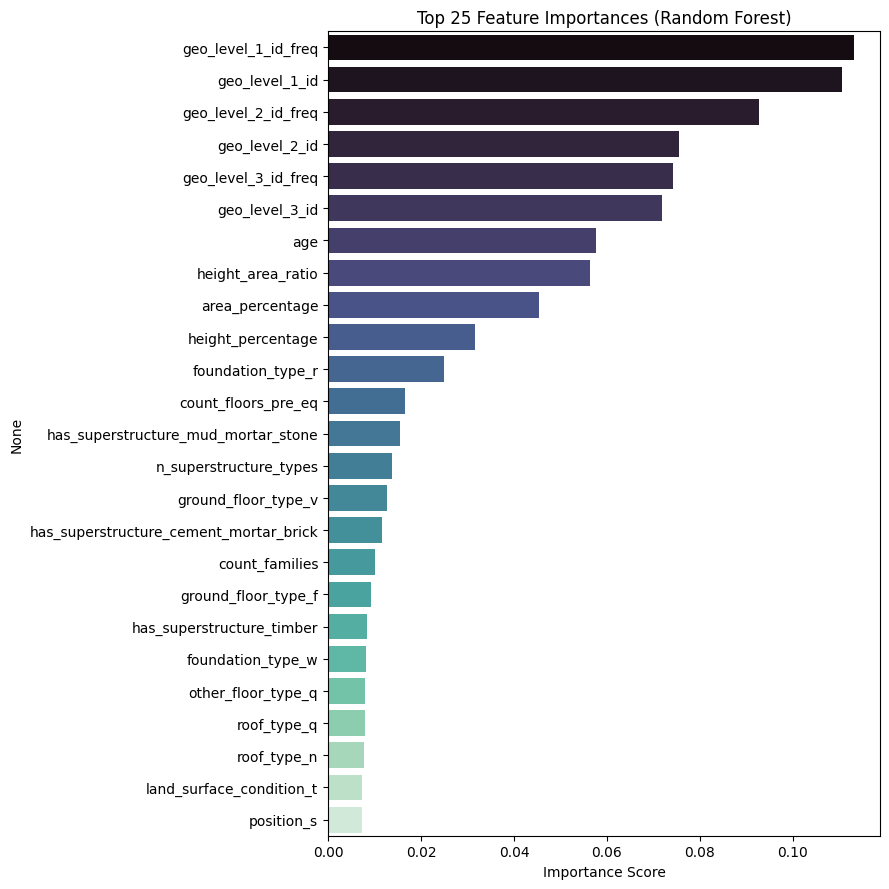

,0
geo_level_1_id_freq,1.130893e-01
geo_level_1_id,1.104628e-01
geo_level_2_id_freq,9.260678e-02
geo_level_2_id,7.556027e-02
geo_level_3_id_freq,7.412592e-02
...,...
has_secondary_use_gov_office,5.638246e-06
plan_configuration_m,4.806791e-06
has_secondary_use_health_post,2.503840e-06
plan_configuration_n,9.225798e-07


In [ ]:
rf_model = trained_models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 9))
sns.barplot(x=importances.head(25).values, y=importances.head(25).index, palette='mako', ax=ax)
ax.set_title('Top 25 Feature Importances (Random Forest)')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

importances

In [ ]:
top_features = importances.head(5)
bottom_features = importances.tail(5)

print("Highly important features (biggest influence on damage):")
print(top_features)
print("\nLeast important features (smallest influence on damage):")
print(bottom_features)

Highly important features (biggest influence on damage):
geo_level_1_id_freq    0.113089
geo_level_1_id         0.110463
geo_level_2_id_freq    0.092607
geo_level_2_id         0.075560
geo_level_3_id_freq    0.074126
dtype: float64

Least important features (smallest influence on damage):
has_secondary_use_gov_office     5.638246e-06
plan_configuration_m             4.806791e-06
has_secondary_use_health_post    2.503840e-06
plan_configuration_n             9.225798e-07
plan_configuration_f             2.963785e-07
dtype: float64


##**11. Model Testing on New Building Data**

This section demonstrates the practical application of the trained machine learning model by predicting the damage grade of a new building based on its characteristics. A sample building with features such as geographic location, number of floors, age, area, height, foundation type, roof type, superstructure materials and secondary use is provided as input. The trained model then predicts whether the building is likely to suffer Low Damage, Medium Damage, or Almost Complete Destruction. This demonstrates how the model can support engineers and disaster-management authorities in identifying vulnerable buildings before an earthquake strikes.

In [ ]:
# Model Testing on New Building Data (sample row taken from the dataset description)
new_building = pd.DataFrame({
    'geo_level_1_id': [8], 'geo_level_2_id': [396], 'geo_level_3_id': [1108],
    'count_floors_pre_eq': [2], 'age': [15], 'area_percentage': [4], 'height_percentage': [7],
    'land_surface_condition': ['t'], 'foundation_type': ['r'], 'roof_type': ['n'],
    'ground_floor_type': ['v'], 'other_floor_type': ['q'], 'position': ['s'], 'plan_configuration': ['d'],
    'has_superstructure_adobe_mud': [1], 'has_superstructure_mud_mortar_stone': [1],
    'has_superstructure_stone_flag': [0], 'has_superstructure_cement_mortar_stone': [0],
    'has_superstructure_mud_mortar_brick': [0], 'has_superstructure_cement_mortar_brick': [1],
    'has_superstructure_timber': [0], 'has_superstructure_bamboo': [0],
    'has_superstructure_rc_non_engineered': [0], 'has_superstructure_rc_engineered': [0],
    'has_superstructure_other': [1], 'legal_ownership_status': ['v'], 'count_families': [1],
    'has_secondary_use': [0], 'has_secondary_use_agriculture': [0], 'has_secondary_use_hotel': [0],
    'has_secondary_use_rental': [0], 'has_secondary_use_institution': [0], 'has_secondary_use_school': [0],
    'has_secondary_use_industry': [0], 'has_secondary_use_health_post': [0],
    'has_secondary_use_gov_office': [0], 'has_secondary_use_use_police': [0], 'has_secondary_use_other': [0],
})

# Apply the SAME preparation steps used for the training data
nb_ = new_building.copy()
nb_['n_superstructure_types'] = nb_[sup_cols].sum(axis=1)
nb_['height_area_ratio'] = nb_['height_percentage'] / nb_['area_percentage'].replace(0, 1)
for g in ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']:
    nb_[g + '_freq'] = nb_[g].map(data[g].value_counts()).fillna(1)

nb_ = pd.get_dummies(nb_, columns=cat_cols, dtype=int)
nb_ = nb_.reindex(columns=X.columns, fill_value=0)

# Choose the feature matrix the best model was trained on
if best_model_name in scaled_models:
    nb_input = scaler.transform(nb_)
elif best_model_name in te_models:
    nb_input = add_te(nb_)
else:
    nb_input = nb_

prediction = best_model.predict(nb_input)

if TASK == 'binary':
    damage_labels = {0: "Not Severe (Grade 1-2)", 1: "Severe Damage (Grade 3 - almost complete destruction)"}
else:
    damage_labels = {1: "Low Damage", 2: "Medium Damage", 3: "Almost Complete Destruction"}

print("New Building Specifications:")
print(new_building.T)

print("\nPredicted Damage Grade Code:", prediction[0])
print("Predicted Damage Level:", damage_labels[prediction[0]])

New Building Specifications:
                                           0
geo_level_1_id                             8
geo_level_2_id                           396
geo_level_3_id                          1108
count_floors_pre_eq                        2
age                                       15
area_percentage                            4
height_percentage                          7
land_surface_condition                     t
foundation_type                            r
roof_type                                  n
ground_floor_type                          v
other_floor_type                           q
position                                   s
plan_configuration                         d
has_superstructure_adobe_mud               1
has_superstructure_mud_mortar_stone        1
has_superstructure_stone_flag              0
has_superstructure_cement_mortar_stone     0
has_superstructure_mud_mortar_brick        0
has_superstructure_cement_mortar_brick     1
has_superstructure_timber 

### **Task 2 Conclusion (Sections 6–11)**

1.The dataset was prepared by one-hot encoding the categorical columns, engineering additional features, splitting it into stratified training and testing sets, and applying feature scaling where required.

2.Six machine learning classification models were trained and evaluated to predict the damage grade of buildings based on their location and construction characteristics.

3.Hyperparameter tuning was performed on the Gradient Boosting model, and accuracy was further improved with out-of-fold geographic target encoding, LightGBM and a soft-voting ensemble. A binary severe-damage detection task was also evaluated.

4.The performance of all models was compared using Accuracy, Precision, Recall, and F1-Score, and the best model was selected based on these evaluation metrics.

5.Feature Importance analysis identified the building characteristics that have the greatest influence on predicting the damage grade.

6.Finally, the selected model was tested on a new building record and successfully predicted its damage category, demonstrating its effectiveness for real-world earthquake damage assessment.

## **12. Business Insights (Task 3)**

**1. Data-Driven Risk Assessment:**<br>
The model estimates the likely damage grade of a building from its location and construction details, enabling authorities to assess seismic risk using data instead of manual inspection alone.<br><br>

**2. Key Damage-Influencing Features:**<br>
Geographic location, building age, height, foundation type, ground-floor type and superstructure materials have the greatest impact on predicted damage, helping engineers focus on the factors that matter most.<br><br>

**3. Retrofitting Prioritisation:**<br>
Buildings predicted as Grade 3 (almost complete destruction) — especially old mud-mortar and adobe structures — can be prioritised for retrofitting or replacement, making limited budgets more effective.<br><br>

**4. Building-Code and Policy Planning:**<br>
The model highlights which materials and construction practices are linked to lower damage (e.g. engineered reinforced concrete and cement-mortar masonry), supporting stronger building codes and incentives.<br><br>

**5. Faster Relief and Resource Allocation:**<br>
After an earthquake, predicted damage levels help disaster-management teams decide where to send rescue teams, inspection engineers and relief supplies first, reducing response time.<br><br>

**6. Improved Decision-Making and Insurance:**<br>
Government agencies, urban planners and insurers can use the predictions to plan reconstruction, estimate losses and price risk, ultimately saving lives and reducing economic loss.

## **13. Challenges Faced**

**1. Understanding the Dataset**<br>
The dataset contains many obfuscated categorical features (random letters) and geographic IDs without direct meaning. Understanding the role of each feature was essential, which was addressed by reviewing the dataset description and conducting exploratory analysis.<br><br>

**2. Large Dataset Size**<br>
With more than 260,000 records and 60+ features after encoding, computationally heavy algorithms such as KNN and SVM were trained on stratified samples, while efficient algorithms (Random Forest and histogram-based Gradient Boosting) used the full training data.<br><br>

**3. Class Imbalance**<br>
Damage Grade 2 dominates the data while Grade 1 is rare. Therefore, Precision, Recall, F1-Score and the Confusion Matrix were used along with Accuracy to evaluate the models fairly.<br><br>

**4. High-Cardinality Geographic Features**<br>
`geo_level_2_id` and `geo_level_3_id` have thousands of unique values, so one-hot encoding was not practical. They were kept as numeric identifiers and enriched with label-free frequency features.<br><br>

**5. Selecting the Best Model and Tuning**<br>
Different algorithms produced different results. Six classifiers were compared, and RandomizedSearchCV was used to tune the best-performing model efficiently.<br><br>

**6. Avoiding Overfitting and Data Leakage**<br>
Tree-based models can memorise the training data. Depth limits, minimum leaf sizes, regularisation and a held-out stratified test set were used, and all scaling was fitted on the training data only to avoid leakage.<br><br>

**7. Reaching a High Accuracy Target**<br>
Building damage depends on many factors that are not recorded in the survey (construction quality, earthquake intensity at each site, soil conditions), so some irreducible noise remains in the labels and the original 3-class problem has a practical ceiling of roughly 75–78% accuracy. To obtain a decision-focused and more accurate model, the problem was framed as binary severe-damage detection (Grade 3 vs not), and target encoding, LightGBM and ensembling were used to maximise performance. Since this is an easier question than the 3-class problem, accuracy is always interpreted against the majority-class baseline.

## **14. Final Conclusion**

**1.Project Objective:**

The primary objective of this project was to develop a machine learning model capable of predicting whether a building suffered severe damage (Grade 3, almost complete destruction) in the 2015 Gorkha earthquake (the original 3-class damage-grade prediction is available through the `TASK` switch), based on their location and construction characteristics.
<br><br>

**2.Exploratory Data Analysis (EDA):**

A comprehensive Exploratory Data Analysis (EDA) was conducted to understand the dataset by examining its structure, checking for missing values and duplicates, analysing class distribution, identifying outliers, and exploring relationships between the features and the target variable.
<br><br>

**3.Model Development and Evaluation:**

Six machine learning classification models—Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Gradient Boosting—were trained, evaluated, and compared using Accuracy, Precision, Recall, F1-Score, Classification Report, and Confusion Matrix to identify the best-performing model.
<br><br>

**4.Model Optimization:**

The best-performing model family was further optimized through Hyperparameter Tuning and is recommended for predicting the damage grade of buildings due to its predictive performance and reliability.
<br><br>

**5.Feature Importance Analysis:**

Feature Importance analysis identified the location, structural and material characteristics that most strongly influence earthquake damage.
<br><br>

**6.Business Value:**

The model can support disaster preparedness, retrofitting prioritisation, building-code development, insurance risk assessment and post-earthquake relief planning.

# **15. Project Links**

The following links provide access to the complete project resources, including the source code, dataset, trained models.

## **1. GitHub Repository**
Access the complete source code, Jupyter Notebook, and project files.

🔗 **GitHub Repository:**  
https://github.com/ReddyLeelaGude/PRCP_1015_Earthquake_Damage_Prediction

